# Assignment 4 - One- and Two-Sample Tests

Group members: Sebastian Bartko, Mariia Moskovko, Matej Palas, Sebastian Halas

Table of contents
1. Part 1 - One-sample decisions
2. Part 2 - Independent coating processes
3. Part 3 - Paired building-energy measurements
4. Part 4 - Comparing two independent proportions
5. Part 5 - AI-use and conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, ttest_1samp, shapiro, binomtest, norm, probplot
from statsmodels.stats.proportion import proportion_confint

In [2]:
sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")
coating = pd.read_csv("data/assignment04_coating_durability.csv")
energy = pd.read_csv("data/assignment04_energy_retrofit.csv")

display(sensors.head())
display(access.head())
display(coating.head())
display(energy.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


,specimen_id,process,durability_h
0,1,standard,112.45
1,2,standard,109.55
2,3,standard,131.35
3,4,standard,130.96
4,5,standard,110.15


,building_id,before_kwh_day,after_kwh_day
0,1,91.57,87.75
1,2,95.33,90.14
2,3,85.20,85.61
3,4,75.96,64.30
4,5,85.33,81.90


# Part 1 - One-sample decisions

## Mean sensor error

Use assignment03_sensor_calibration.csv. The engineering team asks whether population mean calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm{C}$ are regarded as small in practice.

**a.** State $H_0$, the two-sided $H_1$, and $\alpha = 0.05$. Use a one-sample $t$ procedure and report the sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

In [3]:
x = sensors["calibration_error_c"].to_numpy()

mu0 = 0.0
alpha = 0.05
n = x.size
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)
print(f"n = {n}, mean = {xbar:.4f} C, s = {s:.4f} C, SE = {se:.4f} C")
print(f"difference from 0 C: {xbar - mu0:.4f} C")

n = 64, mean = 0.1883 C, s = 0.6257 C, SE = 0.0782 C
difference from 0 C: 0.1883 C


Compute $t$ by hand, then verify with `ttest_1samp` (with `alternative=` set explicitly).

In [4]:
t_obs = (xbar - mu0) / se
df = n - 1
p_two = 2 * t.sf(np.abs(t_obs), df=df)
res = ttest_1samp(x, popmean=mu0, alternative="two-sided")
print(f"manual t = {t_obs:.3f}, df = {df}, p = {p_two:.4g}")
print("SciPy:      ", res)

manual t = 2.407, df = 63, p = 0.01903
SciPy:       TtestResult(statistic=np.float64(2.4069234365872125), pvalue=np.float64(0.019030535831259073), df=np.int64(63))


**b.** Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the decision and a contextual conclusion without treating the $p$-value as $P(H_0 \mid \text{data})$.

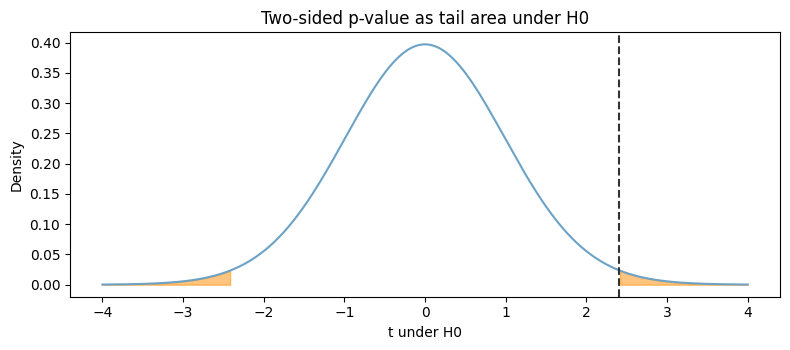

p = 0.0190, alpha = 0.05
Reject H0


In [5]:
grid = np.linspace(-4, 4, 400)
pdf = t.pdf(grid, df=df)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(grid, pdf, color="#6CA2C6")
ax.fill_between(grid, pdf, where=grid <= -abs(t_obs), color="#FF8C00", alpha=0.5)
ax.fill_between(grid, pdf, where=grid >= abs(t_obs), color="#FF8C00", alpha=0.5)
ax.axvline(t_obs, color="0.2", linestyle="--")
ax.set_xlabel("t under H0")
ax.set_ylabel("Density")
ax.set_title("Two-sided p-value as tail area under H0")
plt.tight_layout()
plt.show()

print(f"p = {p_two:.4f}, alpha = {alpha}")
print("Reject H0" if p_two <= alpha else "Fail to reject H0")

**Interpretation of the $p$-value.** If the true mean error were $0$ °C and the assumptions held (independent, representative sensors; $t$ model for the mean), a $t$ statistic at least as extreme as $|t_{obs}| = 2.41$ in either direction would occur with probability about $0.019$ (the orange tail area). It is **not** $P(H_0 \mid \text{data})$: it is a probability about the data assuming $H_0$, not a probability that $H_0$ is true.

**Decision.** $p = 0.019 \le \alpha = 0.05$, so we reject $H_0$.

**c.** Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare it with the practical limits and distinguish statistical significance from practical importance.

In [6]:
ci = t.interval(0.95, df=df, loc=xbar, scale=se)
practical = 0.50
print(f"95% t-interval for mu (C): [{ci[0]:.3f}, {ci[1]:.3f}]")
print("0 C inside the interval?", ci[0] <= mu0 <= ci[1])
print(f"interval inside the practical limits (-{practical}, {practical})?", -practical < ci[0] and ci[1] < practical)

95% t-interval for mu (C): [0.032, 0.345]
0 C inside the interval? False
interval inside the practical limits (-0.5, 0.5)? True


**95% $t$ interval:** $\bar{x} \pm t_{63,\,0.975}\cdot s/\sqrt{n} = [0.032,\ 0.345]$ °C (the same as in Assignment 3).

**Duality.** A two-sided test at $\alpha = 0.05$ rejects $H_0: \mu = \mu_0$ exactly when $\mu_0$ lies outside the 95% $t$ interval, since both use the same estimate, standard error and critical value. Here $0$ °C is outside the interval, matching the rejection in b ($p = 0.019 < 0.05$).

**Practical limits.** The whole interval lies inside $(-0.50,\ 0.50)$ °C; even the largest plausible mean error, about 0.35 °C, is below the limit.

**Significance vs. importance.** The mean error is *statistically* different from zero but *practically small*: every plausible value of $\mu$ is within the range the team regards as small. The $p$-value only says the error is not zero; the interval compared with the limit says it is not large enough to matter. Recalibration is not necessary on this evidence.

## False-rejection probability

Use assignment03_access_control.csv. The pre-specified question is whether the false-rejection probability exceeds the 5% target.

**a.** State the one-sided hypotheses. Perform an exact binomial test and report $\hat{p}$, the $p$-value, decision, and conclusion.

$$H_0: p = 0.05 \qquad \text{versus} \qquad H_1: p > 0.05, \qquad \alpha = 0.05.$$

In [7]:
y = access["false_reject"].to_numpy()
p0 = 0.05
k = int(y.sum())
n_fr = y.size
phat = k / n_fr
res_bin = binomtest(k, n=n_fr, p=p0, alternative="greater")
print(f"k = {k}, n = {n_fr}, phat = {phat:.4f}")
print("exact binomial test:", res_bin)
print("Reject H0" if res_bin.pvalue <= alpha else "Fail to reject H0")

k = 20, n = 240, phat = 0.0833
exact binomial test: BinomTestResult(k=20, n=240, alternative='greater', statistic=0.08333333333333333, pvalue=0.01848556299480277)
Reject H0


**Result.** $k = 20$ false rejections in $n = 240$ attempts, so $\hat{p} = 20/240 = 0.0833$ (8.3%). The exact one-sided $p$-value is $P(K \ge 20 \mid p = 0.05) = 0.018$.

**Decision.** $p = 0.018 \le 0.05$, so we reject $H_0$.

**b.** Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson interval is not the exact dual of a one-sided exact test.

In [8]:
wilson = proportion_confint(k, n_fr, alpha=0.05, method="wilson")
exact_lower = res_bin.proportion_ci(confidence_level=0.95)
print(f"Wilson 95% interval: [{wilson[0]:.4f}, {wilson[1]:.4f}]")
print(f"exact one-sided 95% lower bound (dual of the exact test): {exact_lower.low:.4f}")

Wilson 95% interval: [0.0546, 0.1252]
exact one-sided 95% lower bound (dual of the exact test): 0.0559


**Wilson interval.** The 95% Wilson interval is $[0.055,\ 0.125]$: false-rejection probabilities from about 5.5% to 12.5% are plausible. The whole interval is above 5%, which agrees with the test, and the true rate may be up to about 2.5 times the target.

**Why it is not the exact dual of the one-sided exact test.**

1. **Exact vs. approximate.** The Wilson interval inverts the large-sample *score* test (normal approximation), while the binomial test uses exact tail probabilities, so they can differ near the boundary.
2. **Two-sided vs. one-sided.** A two-sided 95% interval puts 2.5% in each tail, but the one-sided test at $\alpha = 0.05$ puts all 5% in the upper tail. Its exact dual is a one-sided Clopper–Pearson *lower bound*, $p \ge 0.056$, which also excludes 0.05.

Here the two approaches happen to agree, but that is not guaranteed, so we use the Wilson interval only as an estimate of plausible values.

**c.** Describe Type I and Type II errors in one of the two one-sample studies and state an operational consequence of each.

We use the **false-rejection study** ($H_0: p = 0.05$ vs. $H_1: p > 0.05$).

| | $H_0$ true ($p \le 5\%$, target met) | $H_1$ true ($p > 5\%$, target exceeded) |
|---|---|---|
| **Reject $H_0$** | **Type I error** (probability at most $\alpha = 0.05$) | Correct detection (probability = power) |
| **Fail to reject $H_0$** | Correct non-rejection | **Type II error** (probability $\beta$) |

- **Type I error:** we conclude that the false-rejection probability exceeds 5% when in fact the system meets the target. *Operational consequence:* a false alarm. The team spends time and money retuning or replacing a system that works, and may loosen the matching threshold unnecessarily, which can increase the risk of false acceptances (security risk).
- **Type II error:** we fail to detect that the false-rejection probability is above 5% when it really is. *Operational consequence:* the system stays in service while too many legitimate users are locked out, causing delays, support calls and frustrated users, and the service target is silently missed.

Since we rejected $H_0$, the only error we could have made in this study is a Type I error. The probability of a Type II error depends on how far the true $p$ is above 5% and on $n$; a larger sample gives more power to detect a small excess.

# Part 2 - Independent coating processes

The file assignment04_coating_durability.csv contains independent specimens from a standard and modified coating process. Let

$$\delta = \mu_{\text{modified}} - \mu_{\text{standard}},$$

measured in durability hours. An increase of at least 8 hours is considered practically important.

Complete the following tasks:

**a.** Explain why the samples are independent rather than paired. Report group $n$, mean, sample standard deviation, and boxplots.

In [9]:
# TODO

*TODO: answer*

**b.** State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and $p$-value. Do not use a preliminary variance test to switch automatically between pooled and Welch procedures.

In [10]:
# TODO

*TODO: answer*

**c.** Assess independence from the design and distribution shape and unusual observations from group plots or residual diagnostics. State what the plots cannot establish.

In [11]:
# TODO

*TODO: answer*

**d.** Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation that reflects statistical uncertainty and practical importance.

*TODO: answer*

# Part 3 - Paired building-energy measurements

The file assignment04_energy_retrofit.csv records energy use for the same 36 buildings before and after a control-system retrofit. Define the paired difference

$$D = \text{before} - \text{after},$$

so a positive value represents a reduction.

Complete the following tasks:

**a.** Explain the observational unit and why the rows form genuine pairs. Create the difference column and report its mean, standard deviation, and standard error.

In [12]:
# TODO

*TODO: answer*

**b.** Plot the paired values and the distribution or QQ-plot of differences. Diagnose the differences—not the two raw columns separately—for the paired $t$ procedure.

In [13]:
# TODO

*TODO: answer*

**c.** Test $H_0: \mu_D = 0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using `ttest_rel` or an equivalent one-sample procedure applied to the differences.

In [14]:
# TODO

*TODO: answer*

**d.** Explain why an independent-samples test would discard useful pairing. Interpret the estimated reduction and interval in kWh/day and state a practical recommendation.

*TODO: answer*

# Part 4 - Comparing two independent proportions

Two independently assigned software configurations were evaluated using separate requests. Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define the risk difference as $p_A - p_B$.

Complete the following tasks:

**a.** State the observational unit, binary outcome, populations, assumptions, comparison order, and two-sided hypotheses.

*TODO: answer*

**b.** Calculate both sample proportions, their difference in percentage points, and a 95% confidence interval using separate estimated variances.

In [15]:
# TODO

*TODO: answer*

**c.** Test $H_0: p_A = p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value, decision, and contextual conclusion.

In [16]:
# TODO

*TODO: answer*

**d.** State what random sampling and random assignment would each support and why a significant difference alone is not enough for an unrestricted causal claim.

*TODO: answer*

# Part 5 - AI-use and conclusion

## AI-use

State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the final work. A short paragraph or table is sufficient.

*TODO: answer*

## Overall conclusion

Write approximately 150–250 words comparing what the four designs allow you to conclude. Include effects and intervals, not only decisions, and distinguish statistical significance, practical importance, and causal interpretation.

Only use Sessions 7–8. Do not use ANOVA, regression, or chi-square methods.

*TODO: answer*